# Exploratory Data Analysis — Dental Teeth Segmentation


In [1]:
import json
import math
import sys
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import skimage.draw
import skimage.io

ROOT_DIR = Path().resolve().parent
sys.path.append(str(ROOT_DIR))

import importlib

import utils.preprocessing as pp

importlib.reload(pp)


from utils.preprocessing import (
    build_masks,
    class_frequency,
    count_teeth_per_image,
    enhance_contrast,
    load_coco_annotations,
    load_image,
    split_coco_dataset,
)
from utils.visualization import apply_masks, plot_teeth_per_image

DATA_DIR  = ROOT_DIR / 'data'
IMG_DIR   = DATA_DIR / 'images'
ANN_DIR   = DATA_DIR / 'annotations'
VIZ_DIR   = ROOT_DIR / 'outputs' / 'visualizations'
VIZ_DIR.mkdir(parents=True, exist_ok=True)

%matplotlib inline
plt.rcParams['figure.dpi'] = 120


## Dataset Overview

In [2]:
# Loading a random image annotation file
sample = load_coco_annotations(str(ANN_DIR / 'akudental_instances.json'))
print(f"Keys: {list(sample.keys())}\n")

# Dataset overview
print("DATASET OVERVIEW")
print(f"Total images:      {len(sample['images'])}")
print(f"Total annotations: {len(sample['annotations'])}")
print(f"Total categories:  {len(sample['categories'])}")

# Sample image info
print("\nSAMPLE IMAGE INFO")
for k, v in sample['images'][0].items():
    print(f"  {k}: {v}")

# Sample annotation info
print("\nSAMPLE ANNOTATION FORMAT")
for k, v in sample['annotations'][0].items():
    if k == 'segmentation':
        print(f"  segmentation: {len(v)} polygon(s)")
        print(f"    points: {len(v[0])//2} (x,y) pairs")
        print("    format: [x1,y1,x2,y2,...] flat list")
        print(f"    first 8 values: {v[0][:8]}")
    else:
        print(f"  {k}: {v}")

# All categories
print("\n=== CATEGORIES (35 total) ===")
for c in sample['categories']:
    print(f"  id={c['id']:2d}  name={c['name']}")

Keys: ['info', 'licenses', 'categories', 'images', 'annotations']

DATASET OVERVIEW
Total images:      333
Total annotations: 9956
Total categories:  35

SAMPLE IMAGE INFO
  id: 1
  file_name: 1.jpg
  width: 2943
  height: 1435

SAMPLE ANNOTATION FORMAT
  id: 1
  image_id: 1
  category_id: 1
  segmentation: 1 polygon(s)
    points: 12 (x,y) pairs
    format: [x1,y1,x2,y2,...] flat list
    first 8 values: [1450, 526, 1463, 709, 1470, 782, 1468, 820]
  area: 24322.0
  bbox: [1374.0, 502.0, 96.0, 335.0]
  iscrowd: 0

=== CATEGORIES (35 total) ===
  id= 1  name=11 - Central Incisor
  id= 2  name=12 - Lateral Incisor
  id= 3  name=13 - Canine
  id= 4  name=14 - 1st Premolar
  id= 5  name=15 - 2nd Premolar
  id= 6  name=16 - 1st Molar
  id= 7  name=17 - 2nd Molar
  id= 8  name=18 - 3rd Molar
  id= 9  name=21 - Central Incisor
  id=10  name=22 - Lateral Incisor
  id=11  name=23 - Canine
  id=12  name=24 - 1st Premolar
  id=13  name=25 - 2nd Premolar
  id=14  name=26 - 1st Molar
  id=15  name

Number of classes is represented by 32 teeth that an adult
jaw has, on average, plus additional 3 categories that detect fillings, crowns and implants.
There is +1 we add for the background(according to MaskRCNN architecture)

In [8]:

coco = load_coco_annotations(str(ANN_DIR / 'akudental_instances.json'))

# Count annotations per image
teeth_counts = count_teeth_per_image(coco)

print("\nTeeth per image (sample — first 10):")
for name in sorted(teeth_counts.keys())[:10]:
    print(f"  {name}: {teeth_counts[name]}")

print(f"Mean teeth per image:{np.mean(list(teeth_counts.values())):.1f}")
print(f"Min teeth per image: {min(teeth_counts.values())}")
print(f"Max teeth per image: {max(teeth_counts.values())}")


Teeth per image (sample — first 10):
  1.jpg: 41
  10.jpg: 32
  100.jpg: 28
  101.jpg: 31
  102.jpg: 35
  103.jpg: 26
  104.jpg: 27
  105.jpg: 40
  106.jpg: 28
  107.jpg: 30
Mean teeth per image:29.9
Min teeth per image: 8
Max teeth per image: 46


In [6]:
# Verify all images have annotations
anns_by_image = {}
for ann in coco['annotations']:
    anns_by_image.setdefault(ann['image_id'], []).append(ann)

images_with_anns    = sum(1 for img in coco['images'] if img['id'] in anns_by_image)
images_without_anns = len(coco['images']) - images_with_anns

print(f"\nImages with annotations:    {images_with_anns}")
print(f"Images without annotations: {images_without_anns}")



Images with annotations:    333
Images without annotations: 0


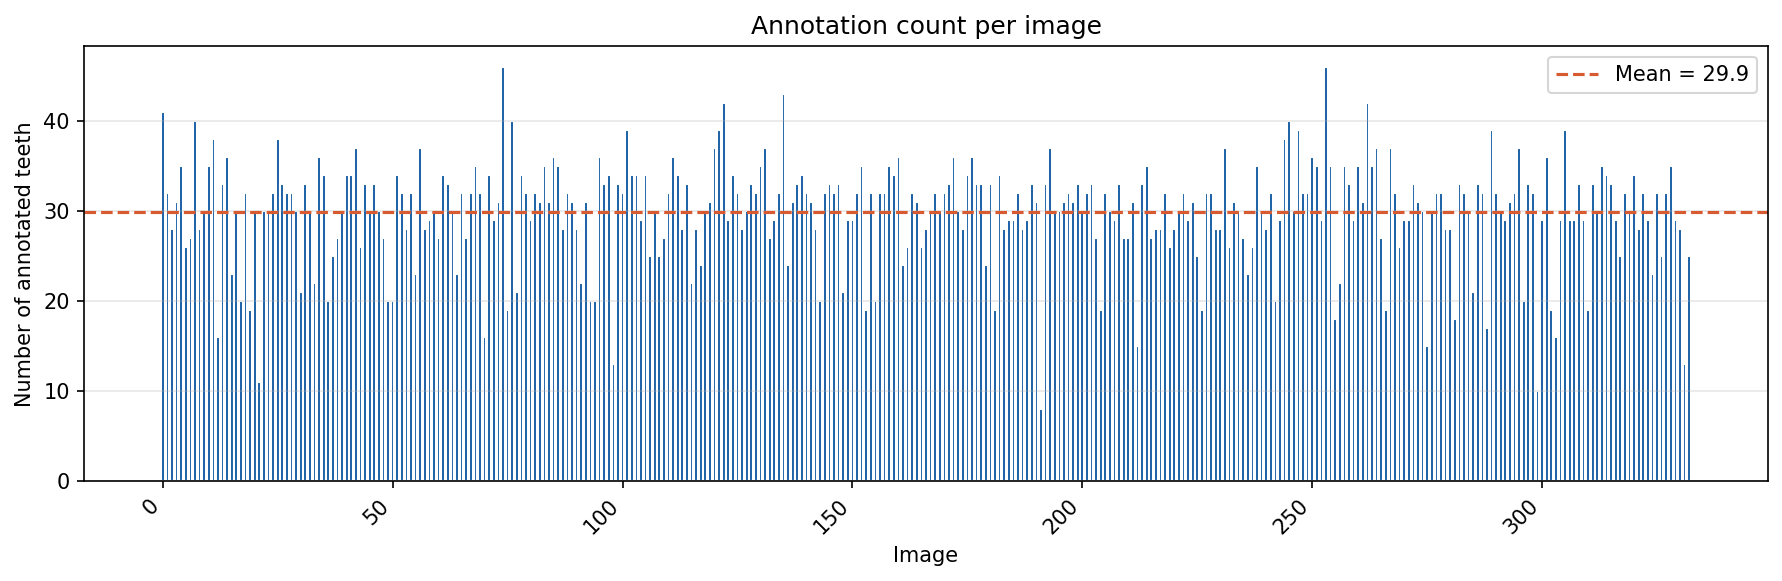

In [9]:
# Plot annotation count per image
# Shows how many teeth/instances are annotated in each of the 333 images
# Useful to spot images with unusually few or many annotations
# Uses image index on x-axis (not filename) — cleaner for 333 images

plot_teeth_per_image(coco, save_path=str(VIZ_DIR / 'teeth_per_image.png'))

from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(str(VIZ_DIR / 'teeth_per_image.png')))

## FDI Frequency (analysis class imbalance)

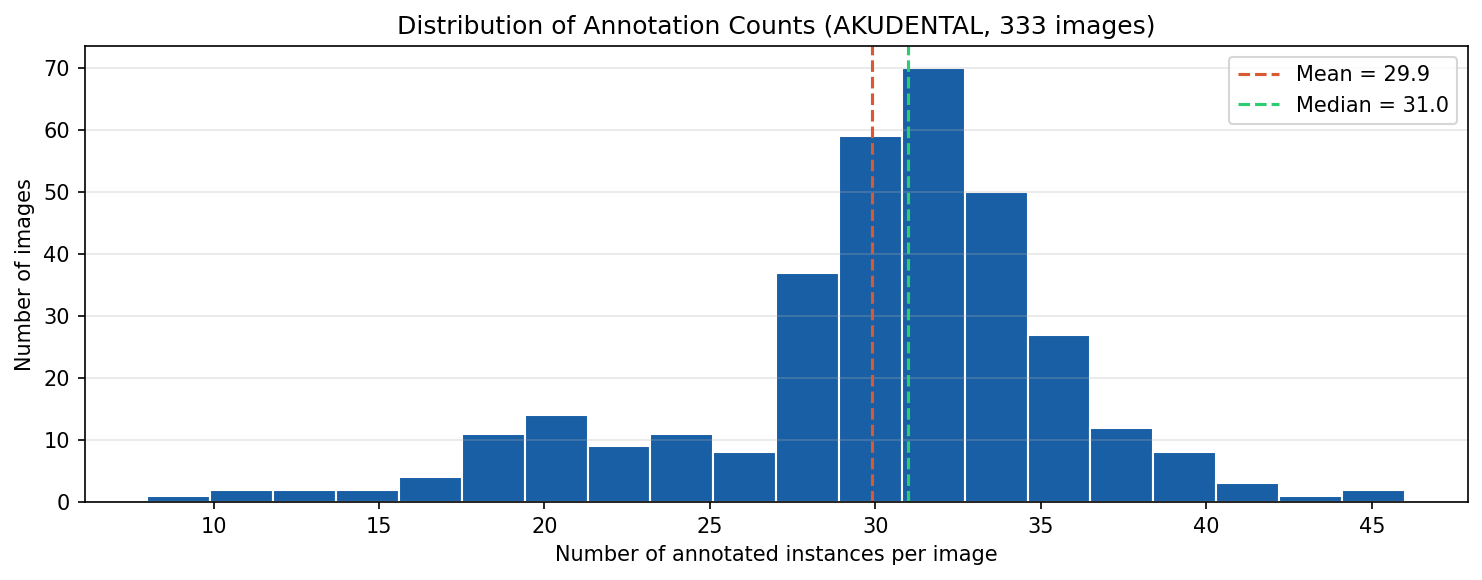

In [11]:
# Distribution of annotation counts across all 333 images
teeth_counts = count_teeth_per_image(coco)
values = list(teeth_counts.values())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(values, bins=20, color="#185FA5", edgecolor="white")
ax.axvline(np.mean(values), color="#D85A30", linestyle="--",
           linewidth=1.5, label=f"Mean = {np.mean(values):.1f}")
ax.axvline(np.median(values), color="#2ECC71", linestyle="--",
           linewidth=1.5, label=f"Median = {np.median(values):.1f}")
ax.set_xlabel("Number of annotated instances per image")
ax.set_ylabel("Number of images")
ax.set_title("Distribution of Annotation Counts (AKUDENTAL, 333 images)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(VIZ_DIR / 'annotation_distribution.png', dpi=150, bbox_inches='tight')
plt.close()

from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(str(VIZ_DIR / 'annotation_distribution.png')))

## Split the dataset and save into train and val.json
PUT THIS IN PREPROCESSING

In [12]:
# Split AKUDENTAL into train/val (80/20) and save
train_coco, val_coco = split_coco_dataset(coco, train_ratio=0.8, seed=42)

print(f"Train: {len(train_coco['images'])} images, {len(train_coco['annotations'])} annotations")
print(f"Val:   {len(val_coco['images'])} images, {len(val_coco['annotations'])} annotations")

with open(ANN_DIR / 'train.json', 'w') as f:
    json.dump(train_coco, f)
with open(ANN_DIR / 'val.json', 'w') as f:
    json.dump(val_coco, f)

print(f"\nSaved train.json and val.json to {ANN_DIR}")

Train: 266 images, 7922 annotations
Val:   67 images, 2034 annotations

Saved train.json and val.json to /home/dorina/Downloads/dental-segmentation-v3/dental-segmentation/data/annotations


### Image dimension properties

In [ ]:
shapes = []
for filename in sorted(IMG_DIR.glob('*.jpg')):
    img = skimage.io.imread(str(filename))
    h, w = img.shape[:2]
    ch   = img.shape[2] if img.ndim == 3 else 1

    # check if grayscale disguised as RGB
    if img.ndim == 3:
        is_true_rgb = not (
            np.array_equal(img[:,:,0], img[:,:,1]) and
            np.array_equal(img[:,:,0], img[:,:,2])
        )
    else:
        is_true_rgb = False

    shapes.append({
        'file': filename.name,
        'h': h, 'w': w, 'ch': ch,
        'min': int(img.min()), 'max': int(img.max()),
        'dtype': str(img.dtype),
        'true_rgb': is_true_rgb
    })

print(f"{'File':<12} {'W':>6} {'H':>6} {'CH':>4} {'Min':>5} {'Max':>5} {'dtype':>8} {'True RGB':>10}")
print('-' * 65)
for s in shapes:
    print(f"{s['file']:<12} {s['w']:>6} {s['h']:>6} {s['ch']:>4} "
          f"{s['min']:>5} {s['max']:>5} {s['dtype']:>8} {s['true_rgb']!s:>10}")

heights = [s['h'] for s in shapes]
widths  = [s['w'] for s in shapes]

print(f'\nHeight: min={min(heights)}  max={max(heights)}  mean={np.mean(heights):.0f}')
print(f'Width:  min={min(widths)}   max={max(widths)}   mean={np.mean(widths):.0f}')

print(f'\n→ IMAGE_MIN_DIM = {min(heights)}')
# Channels = 3 grayscale-as-RGB (False means all 3 channels are identical R=G=B at every pxl)
# Images: ~2907x1444px wide panoramic X-rays
# IMAGE_MIN_DIM = 512 (fits height dimension)
# IMAGE_MAX_DIM = 1024 (must be divisible by 64)

# Mask RCNN resizes internally — no manual resize needed

File              W      H   CH   Min   Max    dtype   True RGB
-----------------------------------------------------------------
1.jpg          2943   1435    3     0   255    uint8      False
10.jpg         2943   1435    3     0   255    uint8      False
100.jpg        2943   1435    3     0   255    uint8      False
101.jpg        2871   1536    3     0   255    uint8      False
102.jpg        2776   1480    3     0   255    uint8      False
103.jpg        2943   1435    3     0   255    uint8      False
104.jpg        2943   1435    3     0   255    uint8      False
105.jpg        2871   1536    3     0   255    uint8      False
106.jpg        2776   1480    3     0   255    uint8      False
107.jpg        2943   1435    3     0   255    uint8      False
108.jpg        2943   1435    3     0   255    uint8      False
109.jpg        2943   1435    3     0   255    uint8      False
11.jpg         2943   1435    3     0   255    uint8      False
110.jpg        2943   1435    3     0 

In [14]:
true_rgb_images = [s['file'] for s in shapes if s['true_rgb']]
false_rgb_images = [s['file'] for s in shapes if not s['true_rgb']]

print(f"True RGB  (real color):  {len(true_rgb_images)} images")
print(f"False RGB (grayscale):   {len(false_rgb_images)} images")
print("\nTrue RGB images:")
for f in true_rgb_images:
    print(f"  {f}")

True RGB  (real color):  5 images
False RGB (grayscale):   328 images

True RGB images:
  111.jpg
  212.jpg
  252.jpg
  275.jpg
  51.jpg


#### Tooth size in pixels -> for figuring out the RPN_ANCHOR_SCALES parameter 

Resize scale: 0.354
Tooth sizes in molded space:
  Width:    mean=38  median=32px
  Height:   mean=82  median=87px
  Diagonal: min=11  mean=93  max=412px

Tooth size range: 5px → 412px
Recommended: RPN_ANCHOR_SCALES = (4, 8, 16, 32, 64, 128, 256, 512)
Current:     RPN_ANCHOR_SCALES = (8, 16, 32, 64, 128)

 Scale |  ratio=0.5 |  ratio=1.0 |  ratio=2.0
---------------------------------------------
     4 |          6 |          6 |          6
     8 |         13 |         11 |         13
    16 |         25 |         23 |         25
    32 |         51 |         45 |         51
    64 |        101 |         91 |        101
   128 |        202 |        181 |        202
   256 |        405 |        362 |        405
   512 |        810 |        724 |        810


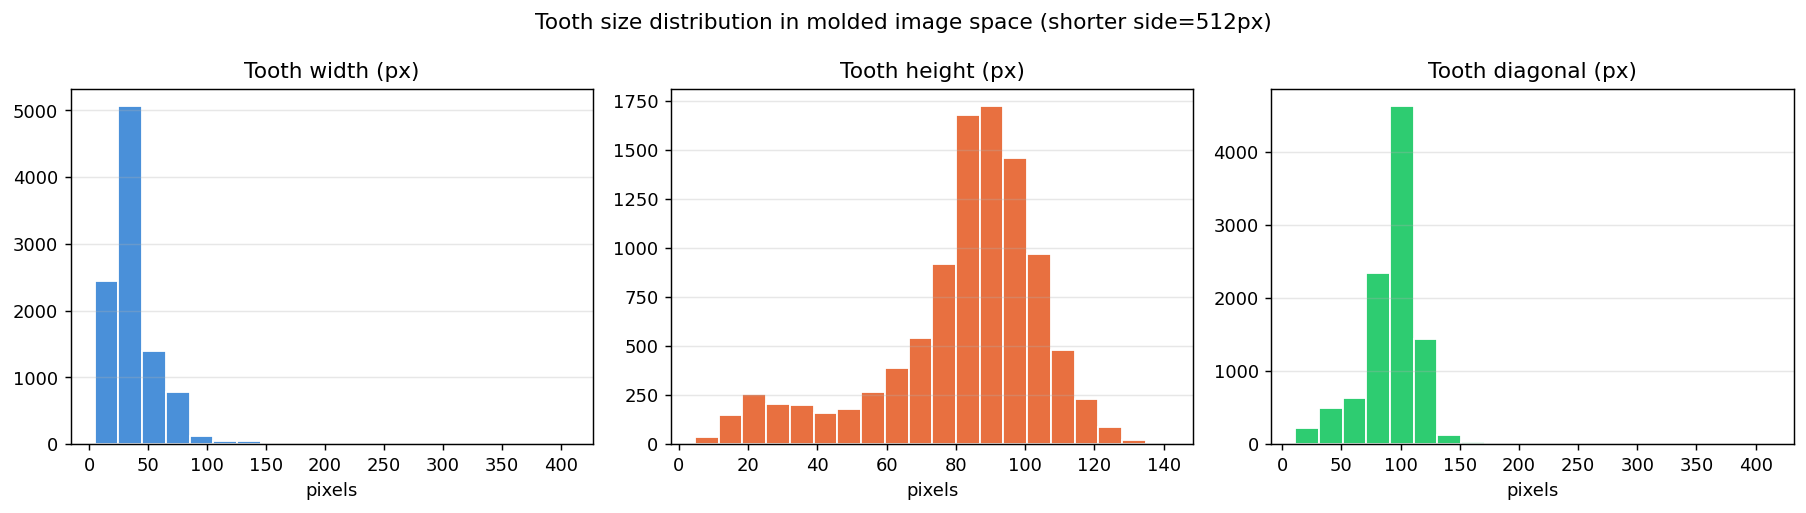

In [ ]:
# ─── Anchor Scale Analysis & Tooth Size Distribution ─────────────────────────

# Collect bbox sizes from all annotations (original image space)
bbox_widths  = [ann['bbox'][2] for ann in coco['annotations']]
bbox_heights = [ann['bbox'][3] for ann in coco['annotations']]

# Convert to molded image space (shorter side → 512px)
resize_scale     = 512 / np.mean([s['h'] for s in shapes])
molded_widths    = [w * resize_scale for w in bbox_widths]
molded_heights   = [h * resize_scale for h in bbox_heights]
molded_diagonals = [np.sqrt(w**2 + h**2) for w, h in zip(molded_widths, molded_heights, strict=False)]

print(f"Resize scale: {resize_scale:.3f}")
print("Tooth sizes in molded space:")
print(f"  Width:    mean={np.mean(molded_widths):.0f}  median={np.median(molded_widths):.0f}px")
print(f"  Height:   mean={np.mean(molded_heights):.0f}  median={np.median(molded_heights):.0f}px")
print(f"  Diagonal: min={min(molded_diagonals):.0f}  mean={np.mean(molded_diagonals):.0f}  max={max(molded_diagonals):.0f}px")

# Compute recommended anchor scales from data
# Start from smallest tooth, double until covering largest
min_size = min(molded_widths + molded_heights)
max_size = max(molded_diagonals)
start    = max(4, 2 ** (math.floor(math.log2(min_size)) - 1))
s        = start
scales   = []
while s < max_size * 1.5:
    scales.append(int(s))
    s *= 2

print(f"\nTooth size range: {min_size:.0f}px → {max_size:.0f}px")
print(f"Recommended: RPN_ANCHOR_SCALES = {tuple(scales)}")

# Show diagonal coverage across all ratios
print(f"\n{'Scale':>6} | {'ratio=0.5':>10} | {'ratio=1.0':>10} | {'ratio=2.0':>10}")
print("-" * 45)
for s in scales[:8]:  # show first 8 to avoid excessive output
    print(f"{s:>6} | "
          f"{s*np.sqrt(0.5+2.0):>10.0f} | "
          f"{s*np.sqrt(1.0+1.0):>10.0f} | "
          f"{s*np.sqrt(2.0+0.5):>10.0f}")

# Plot tooth size distribution in molded space
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(molded_widths,    bins=20, color="#4A90D9", edgecolor='white')
axes[0].set_title("Tooth width (px)")
axes[0].set_xlabel('pixels')
axes[1].hist(molded_heights,   bins=20, color="#E87040", edgecolor='white')
axes[1].set_title("Tooth height (px)")
axes[1].set_xlabel('pixels')
axes[2].hist(molded_diagonals, bins=20, color="#2ECC71", edgecolor='white')
axes[2].set_title("Tooth diagonal (px)")
axes[2].set_xlabel('pixels')
for ax in axes:
    ax.grid(axis='y', alpha=0.3)

plt.suptitle("Tooth size distribution in molded image space (shorter side=512px)")
plt.tight_layout()
plt.savefig(VIZ_DIR / 'tooth_sizes.png', dpi=130, bbox_inches='tight')
plt.close()

from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(str(VIZ_DIR / 'tooth_sizes.png')))

/tmp/ipykernel_1651029/3162382185.py:49: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[4].set_xticklabels(extra_cats.keys(), rotation=45, fontsize=7)


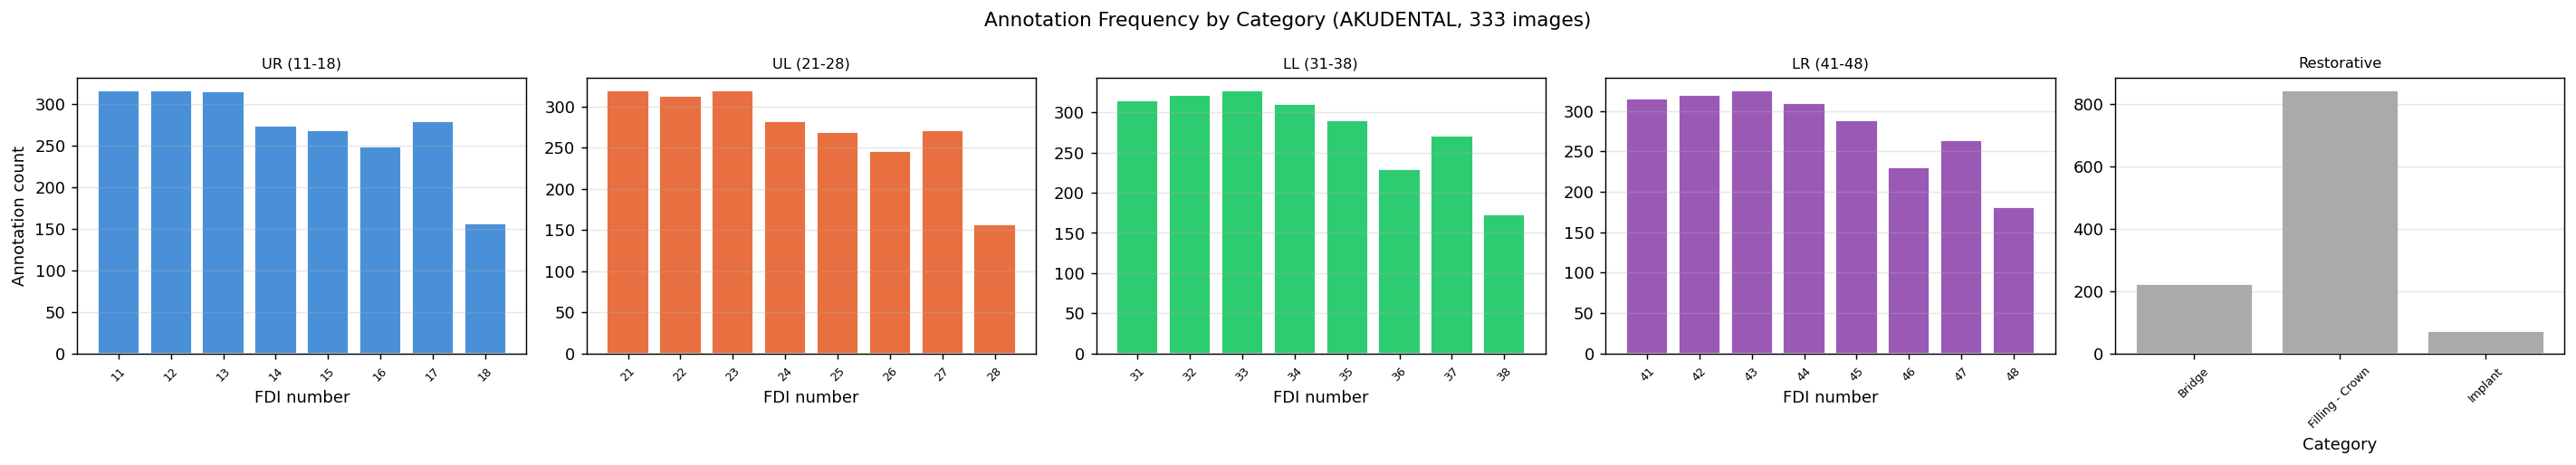

In [23]:
# Per-quadrant FDI annotation frequency + restorative categories

cat_map = {c['id']: c['name'] for c in coco['categories']}
freq    = class_frequency(coco)

# Map FDI category_id → FDI number for teeth only (ids 1-32)
fdi_counts = {}
for cat in coco['categories']:
    if cat['id'] <= 32:
        try:
            fdi = int(cat['name'].split(' ')[0])
            fdi_counts[fdi] = freq.get(cat['id'], 0)
        except ValueError:
            pass

# Restorative categories (ids 33-35)
extra_cats = {cat['name']: freq.get(cat['id'], 0)
              for cat in coco['categories'] if cat['id'] > 32}

quadrants = {
    'UR (11-18)': range(11, 19),
    'UL (21-28)': range(21, 29),
    'LL (31-38)': range(31, 39),
    'LR (41-48)': range(41, 49),
}
quad_colors = ["#4A90D9", "#E87040", "#2ECC71", "#9B59B6"]

# 5 subplots: 4 quadrants + 1 restorative
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
fig.suptitle('Annotation Frequency by Category (AKUDENTAL, 333 images)')

# FDI quadrants
for ax, (qlabel, fdi_range), color in zip(axes[:4], quadrants.items(), quad_colors, strict=False):
    fdi_ids = list(fdi_range)
    counts  = [fdi_counts.get(fdi, 0) for fdi in fdi_ids]
    ax.bar(fdi_ids, counts, color=color, edgecolor='white')
    ax.set_title(qlabel, fontsize=9)
    ax.set_xlabel('FDI number')
    ax.set_xticks(fdi_ids)
    ax.set_xticklabels([str(f) for f in fdi_ids], rotation=45, fontsize=7)
    ax.grid(axis='y', alpha=0.3)

axes[0].set_ylabel('Annotation count')

# Restorative categories
axes[4].bar(extra_cats.keys(), extra_cats.values(), color="#AAAAAA", edgecolor='white')
axes[4].set_title('Restorative', fontsize=9)
axes[4].set_xlabel('Category')
axes[4].set_xticklabels(extra_cats.keys(), rotation=45, fontsize=7)
axes[4].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(VIZ_DIR / 'category_frequency.png', dpi=130, bbox_inches='tight')
plt.close()

from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(str(VIZ_DIR / 'category_frequency.png')))

## Compare different contrast enhacement techniques

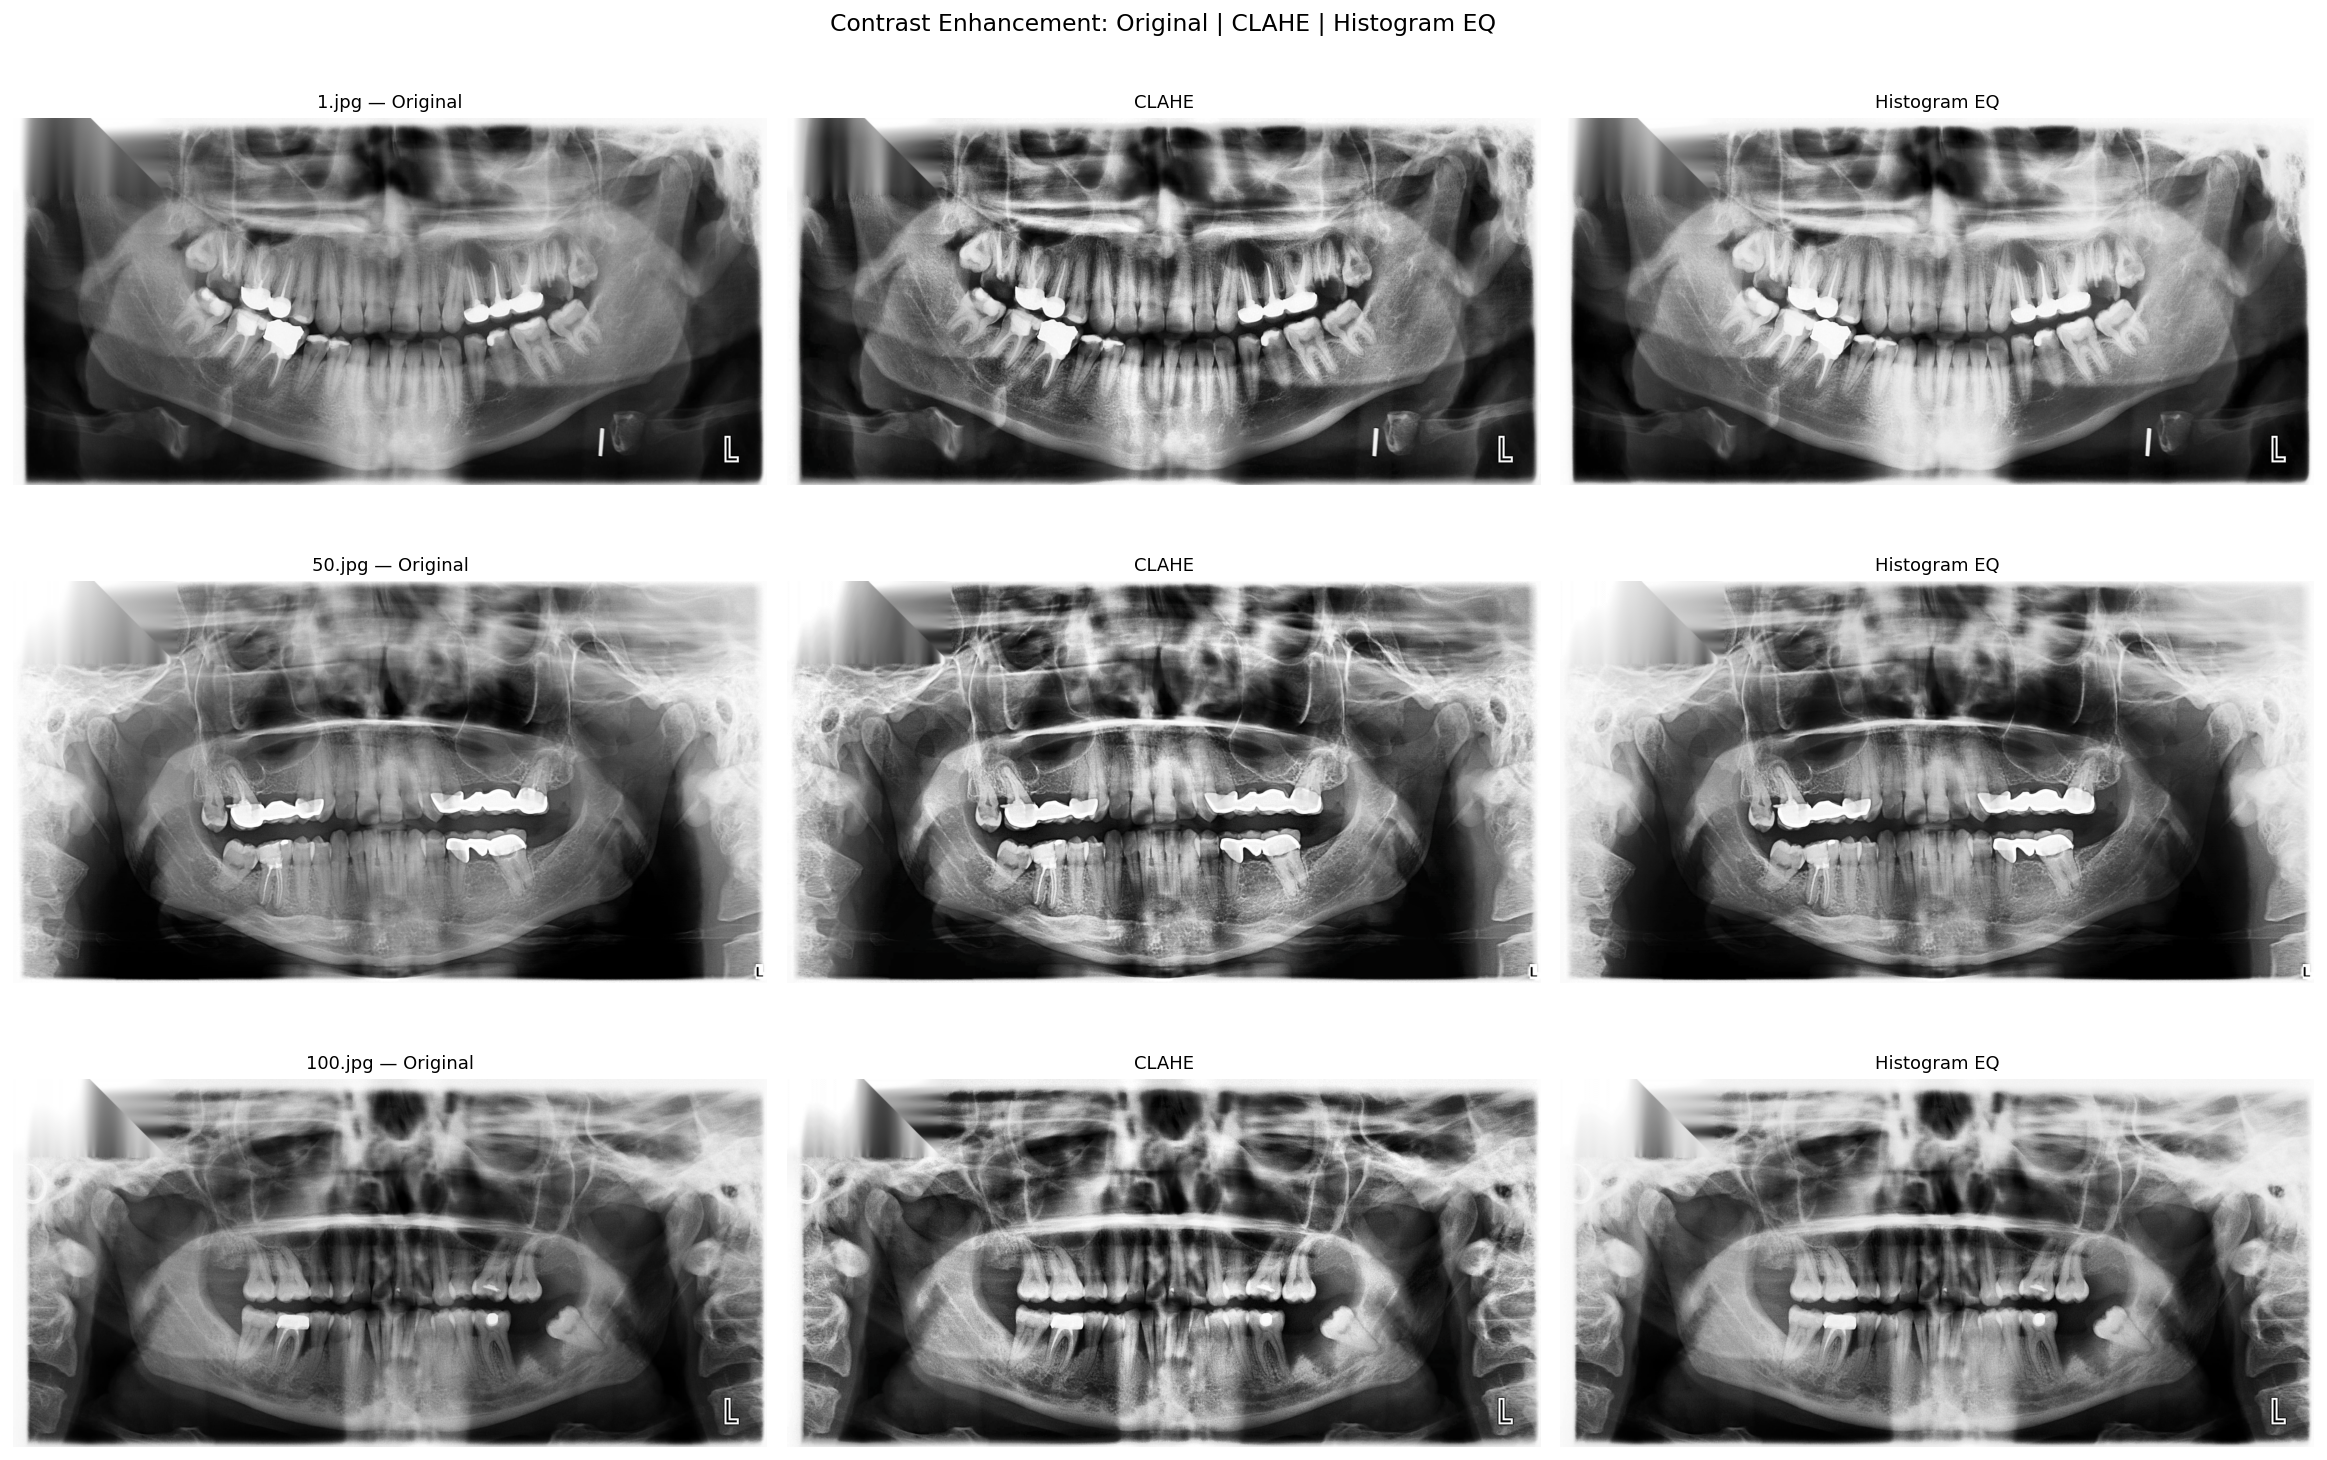

In [24]:
# Shows Original vs CLAHE vs Histogram EQ

sample_files = ['1.jpg', '50.jpg', '100.jpg']

fig, axes = plt.subplots(len(sample_files), 3,
                          figsize=(18, 4 * len(sample_files)))
fig.suptitle('Contrast Enhancement: Original | CLAHE | Histogram EQ', fontsize=13)

for row, fname in enumerate(sample_files):
    orig  = load_image(str(IMG_DIR / fname))
    clahe = enhance_contrast(orig, method='clahe')
    heq   = enhance_contrast(orig, method='histogram_eq')

    for col, (img, title) in enumerate([
        (orig,  f'{fname} — Original'),
        (clahe, 'CLAHE'),
        (heq,   'Histogram EQ'),
    ]):
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(title, fontsize=10)
        axes[row, col].axis('off')

plt.tight_layout()
plt.savefig(VIZ_DIR / 'contrast_comparison.png', dpi=130, bbox_inches='tight')
plt.close()

from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(str(VIZ_DIR / 'contrast_comparison.png')))

## Load annotations on the image

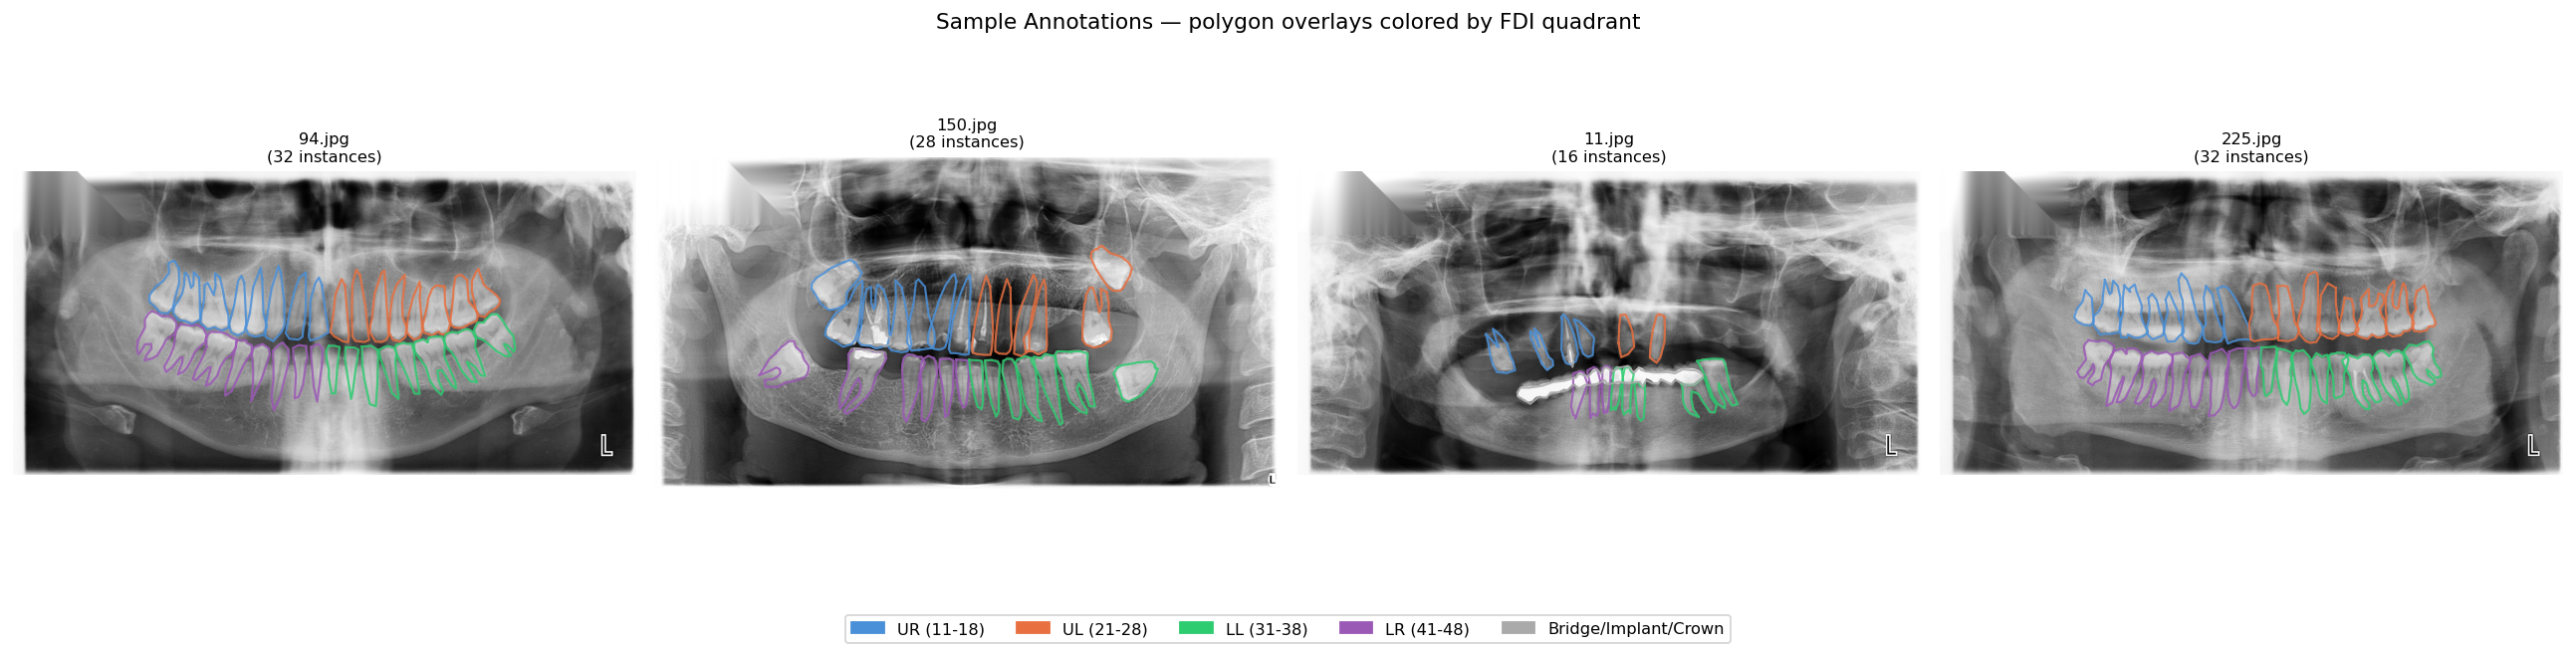

In [25]:
# Show sample annotations with polygon overlays colored by FDI quadrant

import random

random.seed(42)

# FDI number → quadrant color
# category name: "11 - Central Incisor" → extract FDI → color
def get_color_from_cat_id(cat_id, cat_map):
    """Get quadrant color from category id."""
    name = cat_map.get(cat_id, '')
    try:
        fdi = int(name.split(' ')[0])
        if 11 <= fdi <= 18: return '#4A90D9'  # UR blue
        if 21 <= fdi <= 28: return '#E87040'  # UL orange
        if 31 <= fdi <= 38: return '#2ECC71'  # LL green
        if 41 <= fdi <= 48: return '#9B59B6'  # LR purple
    except (ValueError, IndexError):
        pass
    return '#AAAAAA'  # gray for Bridge/Implant/Crown

cat_map = {c['id']: c['name'] for c in coco['categories']}

anns_by_image = {}
for ann in coco['annotations']:
    anns_by_image.setdefault(ann['image_id'], []).append(ann)

# Pick 4 random images
sample_imgs = random.sample(coco['images'], 4)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Sample Annotations — polygon overlays colored by FDI quadrant', fontsize=12)

for ax, img_info in zip(axes, sample_imgs, strict=False):
    img  = load_image(str(IMG_DIR / img_info['file_name']))
    anns = anns_by_image.get(img_info['id'], [])

    ax.imshow(img, cmap='gray')

    for ann in anns:
        seg   = ann['segmentation'][0]
        xs    = seg[0::2] + [seg[0]]  # close the polygon
        ys    = [*seg[1::2], seg[1]]
        color = get_color_from_cat_id(ann['category_id'], cat_map)
        ax.plot(xs, ys, '-', color=color, linewidth=1.2, alpha=0.85)

    ax.set_title(f"{img_info['file_name']}\n({len(anns)} instances)", fontsize=9)
    ax.axis('off')

# Legend
legend_els = [
    mpatches.Patch(color='#4A90D9', label='UR (11-18)'),
    mpatches.Patch(color='#E87040', label='UL (21-28)'),
    mpatches.Patch(color='#2ECC71', label='LL (31-38)'),
    mpatches.Patch(color='#9B59B6', label='LR (41-48)'),
    mpatches.Patch(color='#AAAAAA', label='Bridge/Implant/Crown'),
]
fig.legend(handles=legend_els, loc='lower center', ncol=5, fontsize=9)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig(VIZ_DIR / 'sample_annotations.png', dpi=130, bbox_inches='tight')
plt.close()

from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(str(VIZ_DIR / 'sample_annotations.png')))

## Load masks

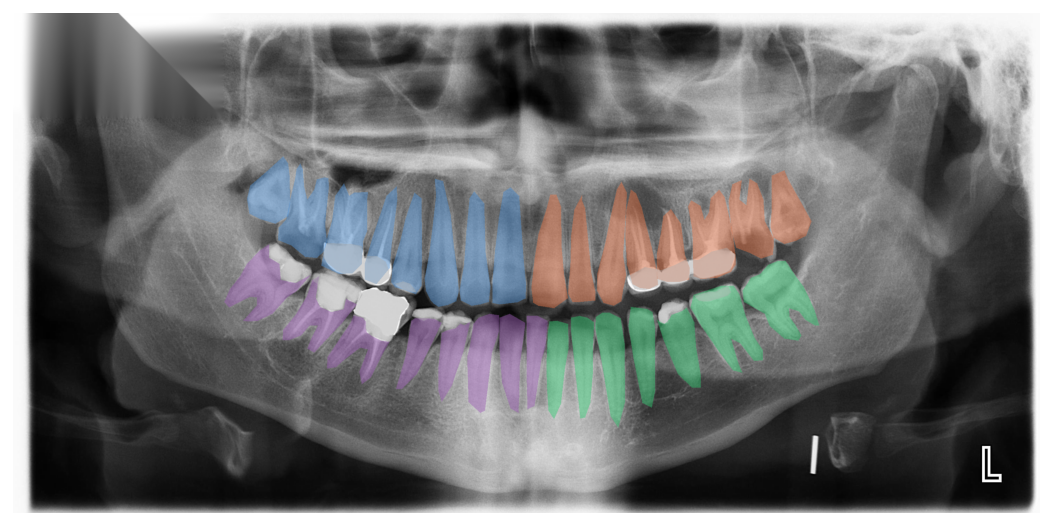

In [26]:
img_info = coco['images'][0]
img      = load_image(str(IMG_DIR / img_info['file_name']))
H, W     = img.shape[:2]

masks, class_ids = build_masks(coco, img_info['file_name'], H, W)

cat_map     = {c['id']: c['name'] for c in coco['categories']}
class_names = [cat_map.get(cid, 'unknown') for cid in class_ids]

annotated = apply_masks(img, masks, class_names=class_names)

plt.figure(figsize=(16, 5))
plt.imshow(annotated)
plt.axis('off')
plt.savefig(VIZ_DIR / 'mask_verification.png', dpi=130, bbox_inches='tight')
plt.close()

from IPython.display import Image as IPImage
from IPython.display import display

display(IPImage(str(VIZ_DIR / 'mask_verification.png')))

## Conclusion

In [ ]:
#Based on the given EDA, the following configuration settings are concluded:
#   NUM_CLASS = 1 + 35
#   IMAGE_MIN_DIM = min(heights)
#   IMAGE_MAX_DIM = 1024
#   DETECTION_MAX_INSTANCES = 45 (represents the max number of instances appearing in dataset)
#   RPN_ANCHOR_SCALE = (16, 32, 64, 128, 256)
#   STEPS_PER_EPOCH = 80% of 333 images
#   VALIDATION STEPS = 20% of 333 images
#   PREPROCESSING = CLAHE - no need for resizing as the model does it by itself
